# JetGuard - Model Error Analysis

Analyze the saved FD001 test predictions from Ridge, Random Forest, and the selected 50-cycle LSTM. This is a descriptive final evaluation, not a tuning step.

Life-stage bands below are exploratory groupings based on true RUL; they are not maintenance thresholds. To stay consistent with the training target and reported metrics, predictions are clipped to 0-125 cycles before scoring.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

ridge = pd.read_csv(REPORT_DIR / "ridge_test_predictions.csv").rename(
    columns={"cycle": "final_cycle", "predicted_RUL": "ridge_raw"}
)
forest = pd.read_csv(REPORT_DIR / "random_forest_test_predictions.csv").rename(
    columns={"cycle": "final_cycle", "predicted_RUL": "forest_raw"}
)
lstm = pd.read_csv(REPORT_DIR / "lstm_test_predictions.csv").rename(
    columns={"predicted_RUL": "lstm_raw"}
)

predictions = ridge[["engine_id", "final_cycle", "true_RUL", "ridge_raw"]].merge(
    forest[["engine_id", "forest_raw"]], on="engine_id", validate="one_to_one"
).merge(
    lstm[["engine_id", "lstm_raw"]], on="engine_id", validate="one_to_one"
).sort_values("engine_id").reset_index(drop=True)

assert len(predictions) == 100
assert predictions["engine_id"].nunique() == 100
assert predictions["true_RUL"].nunique() > 1
assert np.allclose(
    ridge.sort_values("engine_id")["true_RUL"].to_numpy(),
    lstm.sort_values("engine_id")["true_RUL"].to_numpy(),
)

model_columns = {
    "Ridge": "ridge_raw",
    "Random Forest": "forest_raw",
    "LSTM (50-cycle)": "lstm_raw",
}
for model_name, raw_column in model_columns.items():
    predictions[model_name] = predictions[raw_column].clip(0, 125)

print("Engines analyzed:", len(predictions))
print("RUL range:", predictions.true_RUL.min(), "to", predictions.true_RUL.max())
predictions.head()

Engines analyzed: 100
RUL range: 7 to 145


,engine_id,final_cycle,true_RUL,ridge_raw,forest_raw,lstm_raw,Ridge,Random Forest,LSTM (50-cycle)
0,1,31,112,101.764731,122.209269,107.315570,101.764731,122.209269,107.315570
1,2,49,98,109.609844,118.111748,106.207825,109.609844,118.111748,106.207825
2,3,126,69,63.005080,67.206986,59.541710,63.005080,67.206986,59.541710
3,4,106,82,75.481835,104.293631,74.623276,75.481835,104.293631,74.623276
4,5,98,91,93.363162,104.607732,74.844330,93.363162,104.607732,74.844330


In [2]:
def nasa_penalty(y_true, y_pred):
    error = np.asarray(y_pred) - np.asarray(y_true)
    return np.where(
        error < 0,
        np.exp(-error / 13.0) - 1.0,
        np.exp(error / 10.0) - 1.0,
    )


def summarize_errors(frame, actual_column, prediction_column):
    actual = frame[actual_column].to_numpy(dtype=float)
    predicted = frame[prediction_column].to_numpy(dtype=float)
    errors = predicted - actual
    nonzero = np.abs(actual) > 1e-8
    return {
        "RMSE": float(np.sqrt(np.mean(errors**2))),
        "MAE": float(np.mean(np.abs(errors))),
        "MAPE": float(np.mean(np.abs(errors[nonzero] / actual[nonzero]))) if nonzero.any() else np.nan,
        "NASA_score": float(nasa_penalty(actual, predicted).sum()),
        "overestimate_rate": float(np.mean(errors > 0)),
        "mean_signed_error": float(np.mean(errors)),
    }


# Long form makes per-model and per-engine diagnostics easy to aggregate.
long_errors = pd.concat(
    [
        predictions[["engine_id", "final_cycle", "true_RUL"]].assign(
            model=model_name,
            predicted_RUL=predictions[model_name],
        )
        for model_name in model_columns
    ],
    ignore_index=True,
)
long_errors["signed_error"] = long_errors["predicted_RUL"] - long_errors["true_RUL"]
long_errors["absolute_error"] = long_errors["signed_error"].abs()
long_errors["squared_error"] = long_errors["signed_error"] ** 2
long_errors["NASA_penalty"] = nasa_penalty(
    long_errors["true_RUL"], long_errors["predicted_RUL"]
)
long_errors["overestimates_RUL"] = long_errors["signed_error"] > 0
long_errors["life_stage"] = pd.cut(
    long_errors["true_RUL"],
    bins=[-np.inf, 30, 75, np.inf],
    labels=["Late (0-30)", "Middle (31-75)", "Early (>75)"],
)

print("Rows:", len(long_errors), "(one row per engine and model)")
long_errors.head()

Rows: 300 (one row per engine and model)


,engine_id,final_cycle,true_RUL,model,predicted_RUL,signed_error,absolute_error,squared_error,NASA_penalty,overestimates_RUL,life_stage
0,1,31,112,Ridge,101.764731,-10.235269,10.235269,104.760730,1.197518,False,Early (>75)
1,2,49,98,Ridge,109.609844,11.609844,11.609844,134.788489,2.193075,True,Early (>75)
2,3,126,69,Ridge,63.005080,-5.994920,5.994920,35.939070,0.585893,False,Middle (31-75)
3,4,106,82,Ridge,75.481835,-6.518165,6.518165,42.486470,0.651027,False,Early (>75)
4,5,98,91,Ridge,93.363162,2.363162,2.363162,5.584536,0.266575,True,Early (>75)


In [3]:
overall_metrics = pd.DataFrame(
    [
        {"model": model_name, **summarize_errors(long_errors[long_errors.model == model_name], "true_RUL", "predicted_RUL")}
        for model_name in model_columns
    ]
)
overall_metrics.to_csv(REPORT_DIR / "error_analysis_overall_metrics.csv", index=False)
overall_metrics

,model,RMSE,MAE,MAPE,NASA_score,overestimate_rate,mean_signed_error
0,Ridge,16.510996,13.349345,0.302236,420.710882,0.52,0.768335
1,Random Forest,18.376515,13.237893,0.205354,831.565645,0.60,2.702338
2,LSTM (50-cycle),16.860206,12.675821,0.180767,407.595734,0.45,-4.226622


In [4]:
stage_rows = []
for (stage, model_name), group in long_errors.groupby(["life_stage", "model"], observed=True):
    stage_rows.append(
        {
            "life_stage": str(stage),
            "model": model_name,
            "engine_count": int(group.engine_id.nunique()),
            **summarize_errors(group, "true_RUL", "predicted_RUL"),
        }
    )

life_stage_metrics = pd.DataFrame(stage_rows)
life_stage_metrics.to_csv(REPORT_DIR / "error_analysis_by_life_stage.csv", index=False)
life_stage_metrics.sort_values(["life_stage", "MAE"])

,life_stage,model,engine_count,RMSE,MAE,MAPE,NASA_score,overestimate_rate,mean_signed_error
8,Early (>75),Ridge,57,16.987391,13.411409,0.123343,208.581518,0.385965,-5.940710
7,Early (>75),Random Forest,57,19.338945,15.426588,0.147707,294.781777,0.543860,-1.511625
6,Early (>75),LSTM (50-cycle),57,20.597650,17.123655,0.159051,312.295287,0.298246,-9.091595
0,Late (0-30),LSTM (50-cycle),25,4.315887,3.635243,0.212308,11.349818,0.720000,2.068356
1,Late (0-30),Random Forest,25,6.124462,4.433238,0.243392,17.998449,0.680000,3.297146
2,Late (0-30),Ridge,25,12.625934,10.619920,0.699270,63.225886,0.560000,5.113062
3,Middle (31-75),LSTM (50-cycle),18,14.487507,11.147375,0.205726,83.950629,0.555556,2.436101
5,Middle (31-75),Ridge,18,19.475585,16.943676,0.317297,148.903478,0.888889,15.979303
4,Middle (31-75),Random Forest,18,25.291852,18.535711,0.335073,518.785419,0.666667,15.220432


In [5]:
engine_errors = long_errors[
    ["engine_id", "final_cycle", "true_RUL", "model", "predicted_RUL", "signed_error", "absolute_error", "NASA_penalty", "overestimates_RUL", "life_stage"]
].sort_values(["model", "absolute_error"], ascending=[True, False])
engine_errors.to_csv(REPORT_DIR / "error_analysis_per_engine.csv", index=False)

worst_by_model = (
    engine_errors.groupby("model", group_keys=False)
    .head(10)
    .sort_values(["model", "absolute_error"], ascending=[True, False])
)
worst_by_model.to_csv(REPORT_DIR / "error_analysis_worst_engines.csv", index=False)
worst_by_model

,engine_id,final_cycle,true_RUL,model,predicted_RUL,signed_error,absolute_error,NASA_penalty,overestimates_RUL,life_stage
229,30,143,115,LSTM (50-cycle),64.898880,-50.101120,50.101120,46.178218,False,Early (>75)
211,12,217,124,LSTM (50-cycle),77.540960,-46.459040,46.459040,34.650826,False,Early (>75)
278,79,101,63,LSTM (50-cycle),102.310560,39.310560,39.310560,49.960764,True,Middle (31-75)
224,25,48,145,LSTM (50-cycle),106.807970,-38.192030,38.192030,17.875192,False,Early (>75)
238,39,37,142,LSTM (50-cycle),107.352450,-34.647550,34.647550,13.370768,False,Early (>75)
259,60,147,100,LSTM (50-cycle),68.182050,-31.817950,31.817950,10.559812,False,Early (>75)
254,55,113,137,LSTM (50-cycle),106.063640,-30.936360,30.936360,9.801878,False,Early (>75)
282,83,73,137,LSTM (50-cycle),106.796715,-30.203285,30.203285,9.209612,False,Early (>75)
288,89,177,136,LSTM (50-cycle),105.928420,-30.071580,30.071580,9.106699,False,Early (>75)
266,67,71,77,LSTM (50-cycle),106.958180,29.958180,29.958180,19.001715,True,Early (>75)


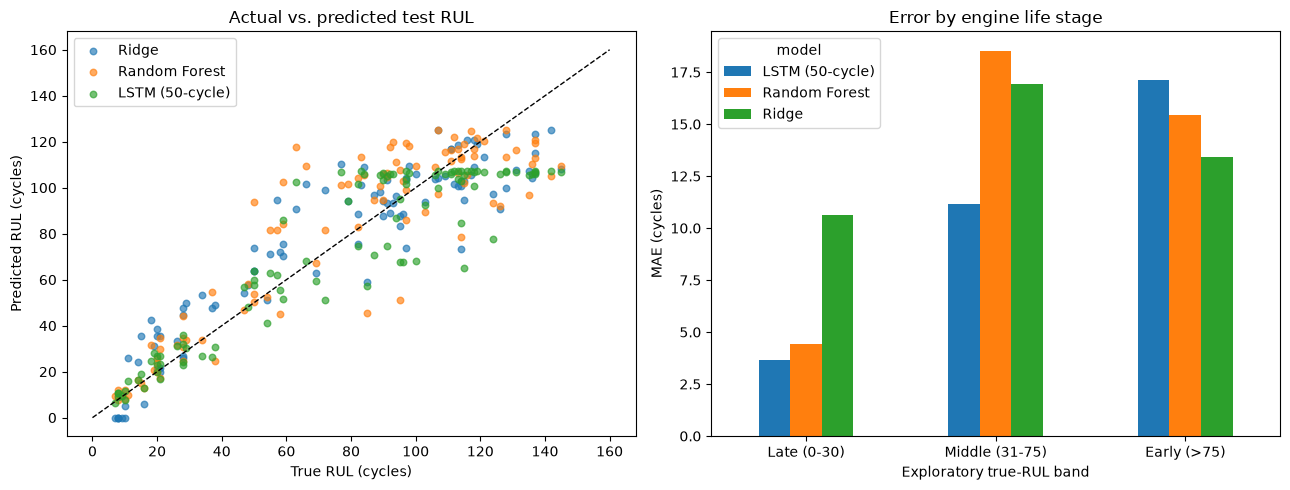

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for model_name in model_columns:
    group = long_errors[long_errors.model == model_name]
    axes[0].scatter(group.true_RUL, group.predicted_RUL, alpha=0.65, s=22, label=model_name)
axes[0].plot([0, 160], [0, 160], "--", color="black", linewidth=1)
axes[0].set(xlabel="True RUL (cycles)", ylabel="Predicted RUL (cycles)", title="Actual vs. predicted test RUL")
axes[0].legend()

stage_order = ["Late (0-30)", "Middle (31-75)", "Early (>75)"]
mae_pivot = life_stage_metrics.pivot(index="life_stage", columns="model", values="MAE").reindex(stage_order)
mae_pivot.plot(kind="bar", ax=axes[1])
axes[1].set(xlabel="Exploratory true-RUL band", ylabel="MAE (cycles)", title="Error by engine life stage")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig(REPORT_DIR / "error_analysis_plots.png", dpi=160, bbox_inches="tight")
plt.show()

In [7]:
print("Per-engine errors:", REPORT_DIR / "error_analysis_per_engine.csv")
print("Life-stage metrics:", REPORT_DIR / "error_analysis_by_life_stage.csv")
print("Overall metrics:", REPORT_DIR / "error_analysis_overall_metrics.csv")
print("Worst engines:", REPORT_DIR / "error_analysis_worst_engines.csv")
print("Plots:", REPORT_DIR / "error_analysis_plots.png")

Per-engine errors: C:\Users\ahzam\Desktop\Projects\JetGuard\reports\error_analysis_per_engine.csv
Life-stage metrics: C:\Users\ahzam\Desktop\Projects\JetGuard\reports\error_analysis_by_life_stage.csv
Overall metrics: C:\Users\ahzam\Desktop\Projects\JetGuard\reports\error_analysis_overall_metrics.csv
Worst engines: C:\Users\ahzam\Desktop\Projects\JetGuard\reports\error_analysis_worst_engines.csv
Plots: C:\Users\ahzam\Desktop\Projects\JetGuard\reports\error_analysis_plots.png
